# 01 · Exploratory Data Analysis: Home Credit Default Risk

**Project:** P1 Credit Risk Service · **Stage 3 (EDA)**
**Data:** Kaggle *Home Credit Default Risk*, stored in `data/raw/` (git-ignored, never redistributed).

Each section answers one question, and its answer decides something in a later stage.

> **Licence rule:** this notebook shows aggregates and plots only, never raw rows (no `head()` or `sample()`).

| # | Section | Decides | Status |
|---|---|---|---|
| 0 | Setup | — | ✅ |
| 1 | Shape and target | Cost-model default rate, stratification, metrics | ✅ |
| 2 | Data quality | Imputation, missing-indicator features, drops | ✅ |
| 3 | Signal | Stage 5 feature-engineering priorities | ✅ |
| 4 | Redundancy | Feature pruning for the logistic regression baseline | ✅ |
| 5 | Fairness groundwork | Base rates for the Stage 6 fairness audit | ✅ |
| 6 | Bureau history | Bureau aggregation plan, leakage check | ✅ |
| 7 | Findings | Summary for the README and Stages 4–6 | ✅ |

---
## 0. Setup

Imports, display options and paths. Paths are built from the repo root with `pathlib`, so the notebook runs on any machine as long as it sits in `notebooks/`. The printed pandas version matters: pandas 3.x loads text as the `str` dtype, pandas 2.x as `object`.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", 50)

print(f"pandas {pd.__version__} | numpy {np.__version__}")

pandas 3.1.1 | numpy 2.5.5


In [2]:
# The notebook runs from notebooks/, so the repo root is one level up.
ROOT = Path.cwd().parent
RAW_DIR = ROOT / "data" / "raw"
TRAIN_PATH = RAW_DIR / "application_train.csv"
TEST_PATH = RAW_DIR / "application_test.csv"

assert RAW_DIR.exists(), f"Raw data folder not found: {RAW_DIR}"

for path in sorted(RAW_DIR.iterdir()):
    print(f"{path.name:<40} {path.stat().st_size / 1024**2:>8.1f} MB")

application_test.csv                         25.3 MB
application_train.csv                       158.4 MB
bureau.csv                                  162.1 MB
bureau_balance.csv                          358.2 MB
credit_card_balance.csv                     404.9 MB
HomeCredit_columns_description.csv            0.0 MB
installments_payments.csv                   689.6 MB
POS_CASH_balance.csv                        374.5 MB
previous_application.csv                    386.2 MB
sample_submission.csv                         0.5 MB


---
## 1. Shape and target

**Question:** How big is the main table, is there exactly one row per applicant, and what is the default rate?

**Decides:** whether the 8% default rate assumed in the Stage 1 cost model holds, how the data is split (stratification), and which metrics are meaningful.

### 1.1 Peek at the column types

Read only the first 1,000 rows at default types to see which dtypes pandas infers, without loading the full 166 MB file.

In [3]:
sample_df = pd.read_csv(TRAIN_PATH, nrows=1_000)
sample_df.dtypes.value_counts()

float64    65
int64      41
str        16
Name: count, dtype: int64

**Result:** 65 `float64`, 41 `int64` and 16 text columns. On pandas 3.x the text columns show as `str` (the dedicated string dtype) rather than the older `object`.

### 1.2 Choose a dtype for each column

| Inferred dtype | Loaded as | Why |
|---|---|---|
| `int64` | `int32` | Halves memory; the value range is checked after loading in 1.3. |
| `float64` | `float32` | About 7 significant digits, enough for EDA and model inputs; precision is checked in 1.3. |
| text | `category` | Few unique values per column, so integer codes plus a lookup table save memory and speed up `groupby`. |

**Risk:** the rule comes from 1,000 rows. If an integer column had a missing value further down the file, `read_csv` would raise a `ValueError`, because an `int32` column cannot hold NaN. A clean full load in 1.3 is the evidence that this did not happen.

Text columns are selected with `exclude="number"`, which works on pandas 2 and 3 without a deprecation warning.

In [4]:
int_cols = sample_df.select_dtypes(include="int64").columns
float_cols = sample_df.select_dtypes(include="float64").columns
text_cols = sample_df.select_dtypes(exclude="number").columns

dtype_map = {
    **{col: "int32" for col in int_cols},
    **{col: "float32" for col in float_cols},
    **{col: "category" for col in text_cols},
}

# Every column must be covered exactly once.
assert len(dtype_map) == sample_df.shape[1], "dtype_map does not cover every column"
print(f"{len(int_cols)} int -> int32 | {len(float_cols)} float -> float32 | {len(text_cols)} text -> category")

41 int -> int32 | 65 float -> float32 | 16 text -> category


### 1.3 Load the full file and measure the saving

Load once at default types only to measure memory, free it, then load with `dtype_map`. `memory_usage(deep=True)` counts the real size of text values, not just pointers to them.

In [5]:
def memory_mb(df: pd.DataFrame) -> float:
    """Return a DataFrame's in-memory size in megabytes (deep, so text is counted)."""
    return df.memory_usage(deep=True).sum() / 1024**2


default_df = pd.read_csv(TRAIN_PATH)
mem_default_mb = memory_mb(default_df)
del default_df  # free the default-typed copy before the typed load

train_df = pd.read_csv(TRAIN_PATH, dtype=dtype_map)
mem_typed_mb = memory_mb(train_df)

print(f"Default dtypes: {mem_default_mb:,.1f} MB")
print(f"Typed load:     {mem_typed_mb:,.1f} MB")
print(f"Reduction:      {1 - mem_typed_mb / mem_default_mb:.0%}")

Default dtypes: 325.2 MB
Typed load:     129.0 MB
Reduction:      60%


In [6]:
# Check 1: every integer value fits comfortably in int32 (about ±2.1 billion).
int_values = train_df.select_dtypes(include="int32")
print(f"Integer range: {int_values.min().min():,} to {int_values.max().max():,}")

# Check 2: float32 precision on the money columns, against a float64 reference.
money_cols = ["AMT_INCOME_TOTAL", "AMT_CREDIT", "AMT_ANNUITY", "AMT_GOODS_PRICE"]
money_f64 = pd.read_csv(TRAIN_PATH, usecols=money_cols)
abs_error = (money_f64 - train_df[money_cols].astype("float64")).abs()

pd.DataFrame({
    "max_value": money_f64.max(),
    "rows_above_2^24": (money_f64 > 2**24).sum(),
    "max_abs_error": abs_error.max(),
})

Integer range: -25,229 to 456,255


,max_value,rows_above_2^24,max_abs_error
AMT_INCOME_TOTAL,117000000.0,2,0.0125
AMT_CREDIT,4050000.0,0,0.0000
AMT_ANNUITY,258025.5,0,0.0000
AMT_GOODS_PRICE,4050000.0,0,0.0000


**Result (pandas 3.1.1):** 325 MB → 129 MB, about 60% less memory. The default figure depends on the pandas version: pandas 2.x stores text as Python `object` strings (about 537 MB in total), while pandas 3.x uses the more compact `str` dtype.
- The load ran without errors, so no integer column has missing values in the full file.
- Integers range from −25,229 to 456,255, well inside `int32`.
- float32 stores whole numbers exactly only up to 2²⁴ = 16,777,216. Only 2 incomes exceed it, and the worst rounding error on any money column is 0.0125, which is negligible.

### 1.4 Structure

In [7]:
print(f"Rows: {train_df.shape[0]:,} | Columns: {train_df.shape[1]}")
print(f"One row per applicant (SK_ID_CURR unique): {train_df['SK_ID_CURR'].is_unique}")

# astype(str): each category column has its own CategoricalDtype, so without it
# value_counts() would list all 16 category columns separately.
train_df.dtypes.astype(str).value_counts()

Rows: 307,511 | Columns: 122
One row per applicant (SK_ID_CURR unique): True


float32     65
int32       41
category    16
Name: count, dtype: int64

**Result:** 307,511 rows × 122 columns (120 features, the ID `SK_ID_CURR` and `TARGET`). `SK_ID_CURR` is unique, so each row is one application, and the history tables must be aggregated *to* this key before joining.

### 1.5 Target and class balance

In [8]:
target_counts = train_df["TARGET"].value_counts().sort_index()
default_rate = train_df["TARGET"].mean()
imbalance_ratio = target_counts[0] / target_counts[1]

print(f"Default rate:    {default_rate:.2%}")
print(f"Imbalance ratio: {imbalance_ratio:.2f} non-defaults per default")

pd.DataFrame({
    "count": target_counts,
    "share_%": (target_counts / len(train_df) * 100).round(2),
}).rename(index={0: "repaid (0)", 1: "default (1)"})

Default rate:    8.07%
Imbalance ratio: 11.39 non-defaults per default


,count,share_%
TARGET,,
repaid (0),282686,91.93
default (1),24825,8.07


**Result:** 24,825 defaults out of 307,511 applications: a **default rate of 8.07%** and **11.39 non-defaults per default**.

### 1.6 Train vs test columns

`application_test.csv` has no `TARGET`, so it cannot be our test set: the hold-out is carved from `application_train` in Stage 4. Here we only check that its columns match what the model will receive at prediction time. `nrows=0` reads the header only.

In [9]:
test_cols = pd.read_csv(TEST_PATH, nrows=0).columns

print("In train, not in test:", sorted(set(train_df.columns) - set(test_cols)))
print("In test, not in train:", sorted(set(test_cols) - set(train_df.columns)))

In train, not in test: ['TARGET']
In test, not in train: []


**Result:** only `TARGET` differs. Every feature available at training time is also present at prediction time.

### 1.7 Findings and implications

1. **The default rate holds.** Measured 8.07% against the 8% assumed in Stage 1. Approve-all floor: 125,000 − 475,000 × 0.0807 ≈ **₦86,670 per application** (was ₦87,000), a negligible change, so the cost model stands. `TARGET` means payment difficulty, not outright default, so C_FN remains an upper bound.
2. **Accuracy is useless here.** Predicting "repaid" for everyone scores 91.9% accuracy and catches no defaulters. Models are compared on PR-AUC (random baseline ≈ 0.081, the default rate, not 0.5), recall at the chosen threshold, and expected profit at the cost threshold p* ≈ 0.26. ROC-AUC is reported too, but it can look strong while precision at a usable threshold is poor.
3. **Stratify every split.** The hold-out and each CV fold keep about 8.07% defaults. A 20% hold-out still contains about 4,965 defaults, enough for stable estimates.
4. **The imbalance is moderate (11.4 : 1).** Try class weights first. SMOTE is an experiment only, fitted inside CV folds through an imblearn Pipeline.
5. **float32 is safe for money columns in EDA and as model inputs** (see 1.3). Profit and cost calculations, and large sums, use float64.
6. **`category` is for EDA only.** The API receives plain strings, and a value never seen in training breaks any encoding built on category codes. Encoding lives inside the sklearn Pipeline (`OneHotEncoder(handle_unknown="ignore")`). When grouping by a category column, pass `observed=` explicitly.
7. **Train and test columns match** apart from `TARGET`.

---
## 2. Data quality

**Question:** Which columns are mostly missing (e.g. the housing block, over 50%)? Which values are placeholders or impossible (`DAYS_EMPLOYED` placeholder, `CODE_GENDER = 'XNA'`, sign of the `DAYS_*` fields)? How extreme are the incomes?

**Decides:** Imputation strategy, missing-indicator features, and which columns to drop.

### 2.1: Missingness Overview

In [10]:
# share of missing values per column
missing_share = train_df.isna().mean().sort_values(ascending=False)

# number of columns with any missing values
n_missing_cols = missing_share[missing_share > 0].shape[0]
print(f"{n_missing_cols} columns have missing values ({n_missing_cols / train_df.shape[1]:.0%})")

# number of columns missing >50% values
n_missing_cols_50 = missing_share[missing_share > 0.5].shape[0]
print(f"{n_missing_cols_50} columns have missing values >50% ({n_missing_cols_50 / train_df.shape[1]:.0%})")

# show top 20 columns with missing values
missing_share.head(20)

67 columns have missing values (55%)
41 columns have missing values >50% (34%)


COMMONAREA_AVG              0.698723
COMMONAREA_MODE             0.698723
COMMONAREA_MEDI             0.698723
NONLIVINGAPARTMENTS_MEDI    0.694330
NONLIVINGAPARTMENTS_MODE    0.694330
NONLIVINGAPARTMENTS_AVG     0.694330
FONDKAPREMONT_MODE          0.683862
LIVINGAPARTMENTS_AVG        0.683550
LIVINGAPARTMENTS_MEDI       0.683550
LIVINGAPARTMENTS_MODE       0.683550
FLOORSMIN_MODE              0.678486
FLOORSMIN_AVG               0.678486
FLOORSMIN_MEDI              0.678486
YEARS_BUILD_AVG             0.664978
YEARS_BUILD_MODE            0.664978
YEARS_BUILD_MEDI            0.664978
OWN_CAR_AGE                 0.659908
LANDAREA_MEDI               0.593767
LANDAREA_AVG                0.593767
LANDAREA_MODE               0.593767
dtype: float64

Result: 67 columns have missing values (55% of the total columns), 41 columns have missing values greater than 50% (34% of the total columns) and the highest missing share is "COMMONAREA_AVG", "COMMONAREA_MODE" and "COMMONAREA_MEDI" having about 69.9% each

### 2.2 which group of columns are missing?


In [11]:
# show the columns with missing values
missing_cols = missing_share[missing_share > 0]
missing_cols.index.tolist()

['COMMONAREA_AVG',
 'COMMONAREA_MODE',
 'COMMONAREA_MEDI',
 'NONLIVINGAPARTMENTS_MEDI',
 'NONLIVINGAPARTMENTS_MODE',
 'NONLIVINGAPARTMENTS_AVG',
 'FONDKAPREMONT_MODE',
 'LIVINGAPARTMENTS_AVG',
 'LIVINGAPARTMENTS_MEDI',
 'LIVINGAPARTMENTS_MODE',
 'FLOORSMIN_MODE',
 'FLOORSMIN_AVG',
 'FLOORSMIN_MEDI',
 'YEARS_BUILD_AVG',
 'YEARS_BUILD_MODE',
 'YEARS_BUILD_MEDI',
 'OWN_CAR_AGE',
 'LANDAREA_MEDI',
 'LANDAREA_AVG',
 'LANDAREA_MODE',
 'BASEMENTAREA_MODE',
 'BASEMENTAREA_MEDI',
 'BASEMENTAREA_AVG',
 'EXT_SOURCE_1',
 'NONLIVINGAREA_MODE',
 'NONLIVINGAREA_AVG',
 'NONLIVINGAREA_MEDI',
 'ELEVATORS_AVG',
 'ELEVATORS_MEDI',
 'ELEVATORS_MODE',
 'WALLSMATERIAL_MODE',
 'APARTMENTS_AVG',
 'APARTMENTS_MEDI',
 'APARTMENTS_MODE',
 'ENTRANCES_MODE',
 'ENTRANCES_MEDI',
 'ENTRANCES_AVG',
 'LIVINGAREA_AVG',
 'LIVINGAREA_MEDI',
 'LIVINGAREA_MODE',
 'HOUSETYPE_MODE',
 'FLOORSMAX_MODE',
 'FLOORSMAX_AVG',
 'FLOORSMAX_MEDI',
 'YEARS_BEGINEXPLUATATION_MODE',
 'YEARS_BEGINEXPLUATATION_MEDI',
 'YEARS_BEGINEXPLUATATIO

In [12]:
# fucntion to map a column name to the data family it belongs to
def column_family(col: str) -> str:
    """Map a column name to the data family it belongs to."""
    if col.endswith(("_AVG", "_MODE", "_MEDI")):
        return "housing"
    if col.startswith("EXT_SOURCE"):
        return "ext_source"
    if col.startswith("AMT_REQ_CREDIT_BUREAU"):
        return "bureau_request"
    if col.endswith(("_SOCIAL_CIRCLE")):
        return "social_circle"
    return "other"

# summarize by family 
missing_family_counts = missing_cols.groupby(missing_cols.index.map(column_family)).agg(["count", "min", "max"]).sort_values(by="count", ascending=False)

# check that nothing was lost in the grouping
assert missing_family_counts["count"].sum() == missing_cols.shape[0], "Grouping lost some columns"
print(missing_family_counts)
print(f"Missing values summary: {missing_family_counts['count'].sum()} columns with missing values ({missing_family_counts['count'].sum() / train_df.shape[1]:.0%})")

                count       min       max
housing            47  0.473983  0.698723
other               7  0.000003  0.659908
bureau_request      6  0.135016  0.135016
social_circle       4  0.003320  0.003320
ext_source          3  0.002146  0.563811
Missing values summary: 67 columns with missing values (55%)


In [13]:
# Equal missing shares do not prove the same rows: compare "any missing" with "all missing".
family_of = pd.Series({col: column_family(col) for col in missing_cols.index})

together = pd.DataFrame({
    family: {
        "rows_missing_any": train_df[cols].isna().any(axis=1).mean(),
        "rows_missing_all": train_df[cols].isna().all(axis=1).mean(),
    }
    for family, cols in family_of.groupby(family_of).groups.items()
    if family != "other"  # "other" holds unrelated columns, so the test is meaningless there
}).T

together.round(4)

,rows_missing_any,rows_missing_all
bureau_request,0.1350,0.1350
ext_source,0.6436,0.0006
housing,0.7444,0.4740
social_circle,0.0033,0.0033


**Result:** If `rows_missing_any` equals `rows_missing_all`, the columns in a family are missing on exactly the same rows. If they differ, each column goes missing on its own.

| Family | any vs all | Reading |
|---|---|---|
| `bureau_request` | 13.5% = 13.5% | Always missing together: one missing pattern for all 6 columns. |
| `social_circle` | 0.33% = 0.33% | Always missing together, and rare. |
| `housing` | 74.4% vs 47.4% | A core block (≈47%) is missing together, but individual columns are also missing on top of that. Not one block. |
| `ext_source` | 64.4% vs 0.06% | Independent: almost nobody misses all three. Each score needs its own handling. |

Housing is the largest family (47 columns), and social circle is the least missing.

### 2.3: Does missingness predict default?

In [14]:
# Check the impact of missing values on the target variable
columns_to_check = ["EXT_SOURCE_1", "OWN_CAR_AGE", "APARTMENTS_AVG"]

pd.DataFrame([
    {
        "column": col,
        "rate_when_missing": train_df.loc[train_df[col].isna(), "TARGET"].mean(),
        "rate_when_present": train_df.loc[train_df[col].notna(), "TARGET"].mean(),
    }
    for col in columns_to_check
]).round(4)

,column,rate_when_missing,rate_when_present
0,EXT_SOURCE_1,0.0852,0.0750
1,OWN_CAR_AGE,0.0850,0.0724
2,APARTMENTS_AVG,0.0915,0.0696


In [15]:
# Three checks behind the conclusions below.

# (a) Housing: does it matter HOW MUCH housing data is missing, or only whether ALL of it is?
housing_cols = family_of.index[family_of == "housing"]
housing_all_missing = train_df[housing_cols].isna().all(axis=1)
housing_any_missing = train_df[housing_cols].isna().any(axis=1)
housing_pattern = np.select(
    [housing_all_missing, housing_any_missing],
    ["all missing", "partly missing"],
    default="complete",
)
display(
    train_df.groupby(housing_pattern)["TARGET"]
    .agg(rows="size", default_rate="mean")
    .round(4)
)

# (b) Car: is a missing OWN_CAR_AGE just "has no car"?
display(pd.crosstab(train_df["FLAG_OWN_CAR"], train_df["OWN_CAR_AGE"].isna().rename("car_age_missing")))

# (c) The three external scores, which are missing independently (see 2.2).
ext_cols = ["EXT_SOURCE_1", "EXT_SOURCE_2", "EXT_SOURCE_3"]
pd.DataFrame([
    {
        "column": col,
        "missing_share": train_df[col].isna().mean(),
        "rate_when_missing": train_df.loc[train_df[col].isna(), "TARGET"].mean(),
        "rate_when_present": train_df.loc[train_df[col].notna(), "TARGET"].mean(),
    }
    for col in ext_cols
]).round(4)

,rows,default_rate
all missing,145755,0.0926
complete,78595,0.0696
partly missing,83161,0.0704


car_age_missing,False,True
FLAG_OWN_CAR,,
N,0,202924
Y,104582,5


,column,missing_share,rate_when_missing,rate_when_present
0,EXT_SOURCE_1,0.5638,0.0852,0.0750
1,EXT_SOURCE_2,0.0021,0.0788,0.0807
2,EXT_SOURCE_3,0.1983,0.0931,0.0777


**Result:** In every column checked, the default rate is higher when the value is missing. For example, 9.15% vs 6.96% for `APARTMENTS_AVG`. This is a descriptive gap, not a cause, but it means **missingness carries signal, so a column is not dropped just because it is mostly missing.**

- **Housing:** rows with *all* housing data missing default at 9.26%. Rows with *partial* data (7.04%) behave like rows with complete data (6.96%). So the useful information is "does this applicant have any housing record at all?" One flag, `HAS_HOUSING_DATA` (true unless all 47 columns are missing), captures it. It is not that the 47 columns always go missing together; 2.2 showed they don't.
- **Car:** `OWN_CAR_AGE` is missing for all 202,924 applicants without a car and for only 5 car owners. Missing car age means "no car", which `FLAG_OWN_CAR` already records. A separate missing-indicator would duplicate it.
- **External scores:** `EXT_SOURCE_3` missing → 9.31% vs 7.77%. `EXT_SOURCE_1` missing → 8.52% vs 7.50%. `EXT_SOURCE_2` is almost never missing (0.2%). Because they are missing independently, each gets its own indicator.

### 2.4: Check the sign of the DAYS_* column

In [16]:
train_df = train_df.copy()  # rebuild into compact memory blocks before adding new columns

# Summarize all day-offset columns and flag any positive maximum.
days_cols = train_df.filter(regex=r"^DAYS_").columns
days_summary = train_df[days_cols].agg(["min", "max"]).T
display(days_summary)

positive_maxima = days_summary.loc[days_summary["max"] > 0, "max"]
print("Columns with a positive (impossible) maximum:")
display(positive_maxima)

# DAYS_BIRTH is negative because it counts days before the application.
train_df["AGE_YEARS"] = -train_df["DAYS_BIRTH"] / 365.25
print(
    f"AGE_YEARS range: {train_df['AGE_YEARS'].min():.2f} to "
    f"{train_df['AGE_YEARS'].max():.2f} years"
)

,min,max
DAYS_BIRTH,-25229.0,-7489.0
DAYS_EMPLOYED,-17912.0,365243.0
DAYS_REGISTRATION,-24672.0,0.0
DAYS_ID_PUBLISH,-7197.0,0.0
DAYS_LAST_PHONE_CHANGE,-4292.0,0.0


Columns with a positive (impossible) maximum:


DAYS_EMPLOYED    365243.0
Name: max, dtype: float64

AGE_YEARS range: 20.50 to 69.07 years


**Result:** All `DAYS_*` columns count days *before* the application, so they should be ≤ 0.
- `DAYS_EMPLOYED` is the only column with an impossible positive maximum (365,243 days ≈ 1,000 years). This is investigated in 2.5.
- Age ranges from 20.5 to 69.1 years: no minors and no implausible ages.
- A maximum of 0 on `DAYS_REGISTRATION`, `DAYS_ID_PUBLISH` and `DAYS_LAST_PHONE_CHANGE` means "on the application day", which is valid.

### 2.5: The days employed placeholder

In [17]:
# Home Credit uses 365243 as a sentinel for DAYS_EMPLOYED, not a real day count.
placeholder_value = 365243
placeholder_rows = train_df["DAYS_EMPLOYED"].eq(placeholder_value)

# Count sentinel rows and measure what fraction of the full dataset they represent.
placeholder_count = int(placeholder_rows.sum())
placeholder_share = placeholder_rows.mean()
print(f"Placeholder rows: {placeholder_count:,} ({placeholder_share:.2%} of all rows)")

# Show which income types make up the sentinel rows, most common first.
# observed=True excludes unused levels of this categorical column.
income_counts = (
    train_df.loc[placeholder_rows]
    .groupby("NAME_INCOME_TYPE", observed=True)
    .size()
    .sort_values(ascending=False)
)
placeholder_income_summary = pd.DataFrame({
    "count": income_counts,
    "share_of_placeholder_rows": income_counts / placeholder_count,
})
display(placeholder_income_summary.round(4))

# TARGET is binary (1 = default), so its mean gives each group's default rate.
default_rate_comparison = pd.DataFrame(
    {
        "rows": [placeholder_count, int((~placeholder_rows).sum())],
        "default_rate": [
            train_df.loc[placeholder_rows, "TARGET"].mean(),
            train_df.loc[~placeholder_rows, "TARGET"].mean(),
        ],
    },
    index=["placeholder", "all other rows"],
)
display(default_rate_comparison.round(4))

# Preserve the sentinel information as an indicator and exclude it from tenure.
train_df["EMPLOYED_PLACEHOLDER"] = placeholder_rows.astype("int8")
train_df["YEARS_EMPLOYED"] = (
    -train_df["DAYS_EMPLOYED"] / 365.25
).where(~placeholder_rows)

Placeholder rows: 55,374 (18.01% of all rows)


,count,share_of_placeholder_rows
NAME_INCOME_TYPE,,
Pensioner,55352,0.9996
Unemployed,22,0.0004


,rows,default_rate
placeholder,55374,0.0540
all other rows,252137,0.0866


**Result:** 55,374 rows (18.0%) hold the placeholder 365243. It is the *only* positive value in the column. 99.96% of these rows are pensioners, and the other 22 are unemployed: the placeholder means **"not currently employed"**, not a broken value.

The group defaults at **5.4% vs 8.7%** for everyone else, so it is real signal. It is kept as the flag `EMPLOYED_PLACEHOLDER`, and `YEARS_EMPLOYED` is set to NaN for these rows (imputed later inside the pipeline).

Why not fill the placeholder with a number such as the minimum? The minimum `DAYS_EMPLOYED` is the *longest* tenure (≈49 years). Assigning it to pensioners would tell the model they are the most stably employed people in the data, which is the opposite of the truth. TRUE!

### 2.6 Other placeholder values

Home Credit also writes `'XNA'` (not available) or `'Unknown'` into some text columns instead of leaving them empty, so `isna()` does not catch them.

In [18]:
# Count hidden placeholders in every text column.
placeholder_tokens = ["XNA", "Unknown"]
hidden = pd.Series({
    col: int(train_df[col].isin(placeholder_tokens).sum())
    for col in train_df.select_dtypes(include="category").columns
})
display(hidden[hidden > 0].sort_values(ascending=False).rename("placeholder_rows"))

# Is ORGANIZATION_TYPE = 'XNA' the same set of rows as the DAYS_EMPLOYED placeholder?
org_xna = train_df["ORGANIZATION_TYPE"].eq("XNA")
print(f"ORGANIZATION_TYPE='XNA': {org_xna.sum():,} rows | "
      f"identical to the DAYS_EMPLOYED placeholder rows: {org_xna.equals(placeholder_rows)}")

ORGANIZATION_TYPE     55374
CODE_GENDER               4
NAME_FAMILY_STATUS        2
Name: placeholder_rows, dtype: int64

ORGANIZATION_TYPE='XNA': 55,374 rows | identical to the DAYS_EMPLOYED placeholder rows: True


**Result:**
- `ORGANIZATION_TYPE = 'XNA'`: 55,374 rows, **exactly** the `DAYS_EMPLOYED` placeholder rows. Same fact (not employed), recorded twice. No extra handling is needed; the one-hot encoder turns it into its own category.
- `CODE_GENDER = 'XNA'`: 4 rows. `NAME_FAMILY_STATUS = 'Unknown'`: 2 rows. These are too few to learn from. Gender is a protected attribute that is excluded from the model anyway (Problem Statement §7). For the fairness audit in Section 5, these 4 rows are left out of the gender comparison.

### 2.7 Extreme money values

In [19]:
# Summarize the tails of the three money columns to spot unusually large values.
money_columns = ["AMT_INCOME_TOTAL", "AMT_CREDIT", "AMT_ANNUITY"]
money_summary = train_df[money_columns].describe(
    percentiles=[0.5, 0.99, 0.999]
)

# Keep the requested percentiles and maximum, with one row per money column.
money_summary = money_summary.loc[["50%", "99%", "99.9%", "max"]].T

# Compare each maximum with its 99th percentile; a larger ratio means a more extreme tail.
money_summary["max_to_99th_percentile"] = (
    money_summary["max"] / money_summary["99%"]
)
display(money_summary)

# Identify the column with the largest max-to-99th-percentile ratio.
most_extreme_column = money_summary["max_to_99th_percentile"].idxmax()
most_extreme_ratio = money_summary.loc[
    most_extreme_column, "max_to_99th_percentile"
]
print(
    f"Most extreme outlier: {most_extreme_column}, "
    f"{most_extreme_ratio:.2f}x its 99th percentile."
)

,50%,99%,99.9%,max,max_to_99th_percentile
AMT_INCOME_TOTAL,147150.0,472500.0,900000.0,117000000.0,247.619048
AMT_CREDIT,513531.0,1854000.0,2517300.0,4050000.0,2.184466
AMT_ANNUITY,24903.0,70006.5,110047.5,258025.5,3.685736


Most extreme outlier: AMT_INCOME_TOTAL, 247.62x its 99th percentile.


In [20]:
# Is the extreme income plausible? Compare it with the loan the same applicants asked for.
# Aggregates only (licence rule): no raw rows are printed.
extreme_income = train_df["AMT_INCOME_TOTAL"] > 10_000_000
income_to_credit = train_df["AMT_INCOME_TOTAL"] / train_df["AMT_CREDIT"]

print(f"Applicants with income > 10M: {extreme_income.sum()} | "
      f"defaults among them: {int(train_df.loc[extreme_income, 'TARGET'].sum())}")
print(f"Income-to-credit ratio: median {income_to_credit.median():.2f} | "
      f"for the top income {income_to_credit.loc[train_df['AMT_INCOME_TOTAL'].idxmax()]:.0f}")

Applicants with income > 10M: 3 | defaults among them: 1
Income-to-credit ratio: median 0.31 | for the top income 208


**Result:** `AMT_CREDIT` and `AMT_ANNUITY` have ordinary tails (max ≈ 2–4× the 99th percentile). `AMT_INCOME_TOTAL` does not. Its maximum, 117M, is 248× the 99th percentile. That applicant is a regular "Working" borrower who asked for a ~560k loan (income ≈ 208× the credit, against a median of 0.31×) and then defaulted. This is almost certainly a data-entry error (extra zeros), not a rich applicant. Only 3 incomes exceed 10M.

**Handling, by model:**
- **Logistic regression** is sensitive to extreme values: one huge income stretches the scale and distorts the coefficient. Use `log1p(income)`, and use ratios such as credit/income (built in Stage 5) instead of raw amounts.
- **Gradient boosting** splits on order, not size, so the outlier barely matters.
- Any clipping cap, such as the 99th percentile, is a *fitted* value. It must be learned inside the pipeline on training folds only, not hardcoded from this notebook.

### 2.8 Findings and implications

1. **Keep mostly-missing columns.** 67 columns have gaps, 41 of them over 50% missing, but missingness predicts default (2.3). Dropping them would discard signal.
2. **Imputation depends on the model.**
   - *Logistic regression (baseline):* median imputation plus a missing-indicator, `SimpleImputer(strategy="median", add_indicator=True)`, fitted **inside** the pipeline on training folds only. A sentinel such as −999 is avoided because a linear model reads it as a real, extremely low value.
   - *LightGBM:* leave NaN as it is. It learns the best direction for missing values at each split.
3. **Engineered missingness flags (Stage 5):** `HAS_HOUSING_DATA` (not all 47 housing columns missing) and one indicator per `EXT_SOURCE_*`. No indicator for `OWN_CAR_AGE`, because `FLAG_OWN_CAR` already covers it.
4. **`DAYS_EMPLOYED = 365243` means "not employed" (pensioners).** Keep it as `EMPLOYED_PLACEHOLDER` and set `YEARS_EMPLOYED` to NaN. The group defaults at 5.4% vs 8.7%. `ORGANIZATION_TYPE = 'XNA'` marks exactly the same rows, so the flag and that category are redundant (Section 4).
5. **Tiny placeholder groups** (`CODE_GENDER='XNA'`, 4 rows; `NAME_FAMILY_STATUS='Unknown'`, 2 rows) need no special handling. `OneHotEncoder(handle_unknown="ignore")` absorbs them.
6. **Income has one implausible value (117M).** Log-transform income for logistic regression. Any clipping is fitted inside the pipeline.
7. **These transformations are row-wise and safe to code once** in `src/credit_risk/features.py`: `YEARS_EMPLOYED`, `EMPLOYED_PLACEHOLDER`, `HAS_HOUSING_DATA`. (`AGE_YEARS` is kept for the fairness audit, not as a model input; see Section 5.) They learn nothing from the data, so they cannot leak.

---
## 3. Signal

**Question:** How does the default rate change across bins or categories of EXT_SOURCE_1/2/3, age, employment length, credit/income and annuity/income ratios, contract type and income type? (Rates, not counts.)

**Decides:** Stage 5 feature-engineering priorities.

### 3.1 Method and a default-rate helper

**Why rates, not counts:** 92% of applicants repay, so any count chart is dominated by repayers. The question is "*within* this group, what share defaulted?", so we always compare the group's default rate with the overall 8.07%.

**Why equal-count bins (`pd.qcut`) instead of equal-width bins (`pd.cut`):** with skewed data such as income, equal-width bins put almost everyone in one or two bins and leave a few people in the rest, so those rates are noise. Deciles give every bin ~30,000 applicants, so every rate is equally reliable.

**Leakage note:** the bin edges here are computed on all of `application_train`. That is fine for *describing* the data. Any binning used as a model feature must be fitted inside the pipeline on training folds only.

In [21]:
def default_rate_by(df: pd.DataFrame, column: str, n_bins: int = 10) -> pd.DataFrame:
    """Default rate per group of `column`.

    Numeric columns with many values are cut into `n_bins` equal-count bins (deciles);
    other columns are grouped by their own values. Missing values form their own group,
    because their default rate is part of the signal (see 2.3).
    """
    values = df[column]
    if pd.api.types.is_numeric_dtype(values) and values.nunique() > n_bins:
        # duplicates="drop": if many rows share one value (e.g. ratio = 1.0), fewer bins are made.
        groups = pd.qcut(values, q=n_bins, duplicates="drop")
    else:
        groups = values

    table = (
        df.groupby(groups, observed=True, dropna=False)["TARGET"]
        .agg(rows="size", default_rate="mean")
    )
    table["lift"] = table["default_rate"] / df["TARGET"].mean()  # 2.0 = twice the average risk
    return table


# Ratio features. Row-wise, so they learn nothing from the data and cannot leak.
train_df["CREDIT_TO_INCOME"] = train_df["AMT_CREDIT"] / train_df["AMT_INCOME_TOTAL"]    # loan size vs income
train_df["ANNUITY_TO_INCOME"] = train_df["AMT_ANNUITY"] / train_df["AMT_INCOME_TOTAL"]  # repayment burden
train_df["CREDIT_TO_GOODS"] = train_df["AMT_CREDIT"] / train_df["AMT_GOODS_PRICE"]      # amount financed above the goods price

default_rate_by(train_df, "EXT_SOURCE_3").round(4)

,rows,default_rate,lift
EXT_SOURCE_3,,,
"(-0.000473, 0.228]",24701,0.2000,2.4778
"(0.228, 0.33]",24744,0.1275,1.5799
"(0.33, 0.408]",25057,0.0951,1.1781
"(0.408, 0.476]",24689,0.0798,0.9884
"(0.476, 0.535]",24186,0.0618,0.7652
"(0.535, 0.592]",25392,0.0534,0.6620
"(0.592, 0.643]",24725,0.0474,0.5877
"(0.643, 0.694]",24745,0.0421,0.5221
"(0.694, 0.749]",23675,0.0353,0.4374


### 3.2 Numeric features

Each panel shows one feature split into 10 equal-sized groups (deciles), from lowest to highest value. A bar above the dashed line means that group is riskier than average.

**How to read a panel:** a steady staircase (monotonic) is easy for every model, including logistic regression. A hump or U-shape is easy for trees but needs extra work (bins or splines) for a linear model.

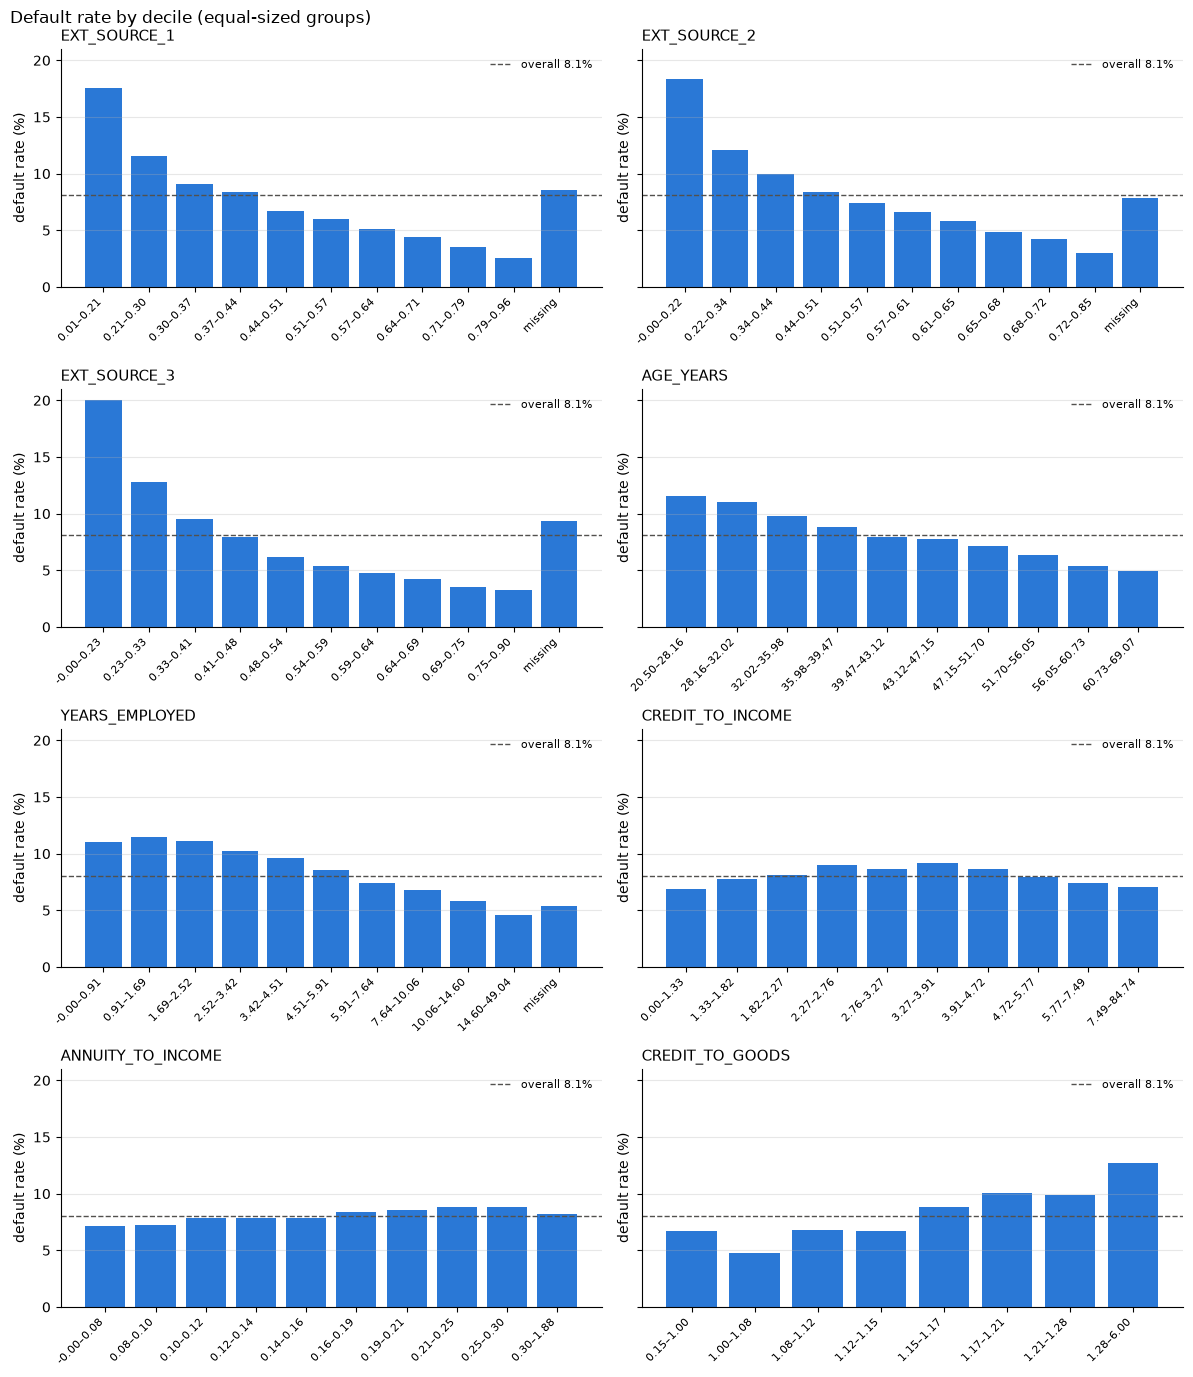

In [22]:
numeric_features = [
    "EXT_SOURCE_1", "EXT_SOURCE_2", "EXT_SOURCE_3",
    "AGE_YEARS", "YEARS_EMPLOYED",
    "CREDIT_TO_INCOME", "ANNUITY_TO_INCOME", "CREDIT_TO_GOODS",
]
MIN_ROWS_TO_PLOT = 500  # smaller groups give unstable rates (e.g. 12 rows with no annuity)

# sharey=True puts every panel on the same scale, so bar heights compare across features.
fig, axes = plt.subplots(4, 2, figsize=(12, 14), sharey=True)
for ax, col in zip(axes.flat, numeric_features):
    table = default_rate_by(train_df, col)
    table = table[table["rows"] >= MIN_ROWS_TO_PLOT]
    labels = [
        "missing" if pd.isna(interval) else f"{interval.left:.2f}–{interval.right:.2f}"
        for interval in table.index
    ]
    ax.bar(range(len(table)), table["default_rate"] * 100, color="#2a78d6", width=0.8)
    ax.axhline(default_rate * 100, color="#52514e", linestyle="--", linewidth=1,
               label=f"overall {default_rate:.1%}")
    ax.set_xticks(range(len(table)), labels, rotation=45, ha="right", fontsize=8)
    ax.set_title(col, loc="left", fontsize=11)
    ax.set_ylabel("default rate (%)")
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(axis="y", alpha=0.3)
    ax.legend(frameon=False, fontsize=8)

fig.suptitle("Default rate by decile (equal-sized groups)", x=0.01, ha="left")
fig.tight_layout()
plt.show()

**Result (overall default rate 8.07%, dashed line):**
- **`EXT_SOURCE_1/2/3`: by far the strongest.** The worst decile defaults at 17.6% / 18.4% / 20.0%, the best at 2.6% / 3.0% / 3.2%. The steps are smooth and monotonic: higher score, lower risk. Missing `EXT_SOURCE_3` sits *above* average (9.3%), as found in 2.3.
- **`AGE_YEARS`:** monotonic, from 11.6% (age 20–28) down to 4.9% (61+).
- **`YEARS_EMPLOYED`:** about 11% in the first 2.5 years, falling to 4.6% after 14.6 years. The placeholder group (pensioners, "missing") sits at 5.4%, close to the longest-tenure bin.
- **`CREDIT_TO_GOODS`:** loans at or below the goods price default at about 5–7%. Loans more than ~15% above it default at 9–13%.
- **`CREDIT_TO_INCOME`:** *not* monotonic. Risk rises to ~9% in the middle bins and falls back to ~7% at both ends.
- **`ANNUITY_TO_INCOME`:** weak, rising gently from 7.1% to 8.9%.

### 3.3 Categorical features

For categories, the **row count matters as much as the rate**. A group of 20 applicants with 3 defaults shows 15%, but that number would swing wildly with a different sample.

In [23]:
categorical_features = ["NAME_CONTRACT_TYPE", "NAME_INCOME_TYPE", "NAME_EDUCATION_TYPE"]

for col in categorical_features:
    display(default_rate_by(train_df, col).sort_values("default_rate").round(4))

,rows,default_rate,lift
NAME_CONTRACT_TYPE,,,
Revolving loans,29279,0.0548,0.6786
Cash loans,278232,0.0835,1.0338


,rows,default_rate,lift
NAME_INCOME_TYPE,,,
Businessman,10,0.0000,0.0000
Student,18,0.0000,0.0000
Pensioner,55362,0.0539,0.6672
State servant,21703,0.0575,0.7129
Commercial associate,71617,0.0748,0.9271
Working,158774,0.0959,1.1877
Unemployed,22,0.3636,4.5044
Maternity leave,5,0.4000,4.9549


,rows,default_rate,lift
NAME_EDUCATION_TYPE,,,
Academic degree,164,0.0183,0.2266
Higher education,74863,0.0536,0.6633
Incomplete higher,10277,0.0848,1.0510
Secondary / secondary special,218391,0.0894,1.1074
Lower secondary,3816,0.1093,1.3536


**Result:**
- **Contract type:** cash loans 8.35% vs revolving loans 5.48%.
- **Income type:** working 9.6%, commercial associate 7.5%, state servant 5.8%, pensioner 5.4%. Unemployed (22 rows, 36%) and maternity leave (5 rows, 40%) look alarming, but with so few rows the rates are not reliable. One more default would move them by several points. The one-hot encoder still creates their columns, and regularisation keeps the model from leaning on them.
- **Education:** a clean gradient, from academic degree (1.8%, only 164 rows) and higher education (5.4%) up to lower secondary (10.9%).

### 3.4 Ranking the signal

To compare features side by side, each one gets a single number: the **spread**, the gap in percentage points between its riskiest and safest group. It is simple and easy to explain, but rough. It ignores group sizes and the shape of the curve, so it is used only to set priorities, not to select features.

In [24]:
def signal_spread(df: pd.DataFrame, column: str, min_rows: int = 500) -> float:
    """Gap between the riskiest and safest group, in percentage points (groups >= min_rows only)."""
    table = default_rate_by(df, column)
    table = table[table["rows"] >= min_rows]
    return (table["default_rate"].max() - table["default_rate"].min()) * 100


(
    pd.Series({col: signal_spread(train_df, col) for col in numeric_features + categorical_features})
    .sort_values(ascending=False)
    .round(1)
    .rename("spread_pp")
    .to_frame()
)

,spread_pp
EXT_SOURCE_3,16.8
EXT_SOURCE_2,15.4
EXT_SOURCE_1,15.0
CREDIT_TO_GOODS,8.0
YEARS_EMPLOYED,6.9
AGE_YEARS,6.7
NAME_EDUCATION_TYPE,5.6
NAME_INCOME_TYPE,4.2
NAME_CONTRACT_TYPE,2.9
CREDIT_TO_INCOME,2.3


**Result:** `EXT_SOURCE_3` (16.8 pp), `EXT_SOURCE_2` (15.4) and `EXT_SOURCE_1` (15.0) lead by a wide margin. Next come `CREDIT_TO_GOODS` (8.0), `YEARS_EMPLOYED` (6.9), `AGE_YEARS` (6.7) and education (5.6). `CREDIT_TO_INCOME` (2.3) and `ANNUITY_TO_INCOME` (1.7) are the weakest.

### 3.5 Findings and implications

1. **The three `EXT_SOURCE` scores dominate.** The default rate runs from ~18–20% in the worst decile to ~3% in the best, a 6–7× range, and the relationship is monotonic. They are the core of every model. Interactions such as their mean or product are the first Stage 5 features to try.
2. **Age and employment length are steady, monotonic signals.** Younger applicants and shorter tenure mean more risk. The employment placeholder (pensioners, 5.4%) behaves like long tenure, which confirms the `EMPLOYED_PLACEHOLDER` flag from 2.5.
3. **`CREDIT_TO_GOODS` is the strongest engineered ratio.** When the loan exceeds the price of the goods by more than ~15%, risk rises to ~10–13%. The extra amount is likely financed fees or insurance. This is a Stage 5 feature.
4. **`CREDIT_TO_INCOME` is hump-shaped, not monotonic.** Risk peaks in the middle (~9%) and is lower at both ends. A logistic regression on the raw ratio fits one straight slope and will miss this. Binning or a spline helps LR; LightGBM finds it on its own. Expect it to matter more for the boosted model.
5. **`ANNUITY_TO_INCOME` is weak** (7.1% → 8.9%). Keep it, but don't expect much.
6. **Categories:** education gives a clear gradient (higher education 5.4%, lower secondary 10.9%). Cash loans are riskier than revolving (8.4% vs 5.5%). Income-type groups under 500 rows are noise.
7. **Caveat:** this is one feature at a time. Strong features may overlap (older applicants also have longer tenure). Section 4 checks redundancy. The final word on feature value comes from cross-validated model performance in Stages 4–5.

---
## 4. Redundancy

**Question:** Which features are near-duplicates (`_AVG` / `_MODE` / `_MEDI` housing triplets, `AMT_CREDIT` vs `AMT_GOODS_PRICE`)?

**Decides:** Feature pruning for the logistic regression baseline.

### 4.1 Method

Two features are **redundant** when one can be predicted almost perfectly from the other. Why it matters:
- **Logistic regression:** near-duplicate inputs make coefficients unstable. The model can split the effect between the twins in any proportion, so a coefficient can even flip sign between CV folds. This is also known as *multicollinearity*.
- **Explanations (`/explain`):** SHAP divides credit between twins, so a real reason ("high debt") shows up as two weaker reasons.
- **Trees (LightGBM)** are barely affected in accuracy, but their feature importance is split the same way.

**How:** Spearman rank correlation between every pair of numeric columns, flagging pairs with |ρ| > 0.9.
- *Spearman, not Pearson:* it compares ranks, so it catches any monotonic relationship and is not distorted by outliers such as the 117M income (2.7).
- *A 50,000-row random sample* (`random_state=42`, so it is reproducible): a correlation estimated from 50k rows is accurate to about ±0.01, and the full 110 × 110 matrix on 307k rows is slow.
- *0.9 is a convention, not a law.* Above it, the second feature adds very little new information.

In [25]:
SEED = 42  # fixed seed so the sample, and therefore every number below, is reproducible

numeric_df = (
    train_df.select_dtypes("number")
    .drop(columns=["SK_ID_CURR", "TARGET"])  # an ID and the target are not features
    .sample(n=50_000, random_state=SEED)
)
spearman = numeric_df.corr(method="spearman").abs()

# Keep each pair once: the upper triangle, excluding the diagonal (a column with itself = 1).
upper = np.triu(np.ones(spearman.shape, dtype=bool), k=1)
pairs = spearman.where(upper).stack().rename("abs_spearman")
high_pairs = pairs[pairs > 0.9].sort_values(ascending=False)


def housing_stem(col: str) -> str | None:
    """'APARTMENTS_AVG' -> 'APARTMENTS'; None for non-housing columns."""
    for suffix in ("_AVG", "_MODE", "_MEDI"):
        if col.endswith(suffix):
            return col[: -len(suffix)]
    return None


is_triplet = [housing_stem(a) is not None and housing_stem(a) == housing_stem(b) for a, b in high_pairs.index]
print(f"{len(high_pairs)} pairs with |rho| > 0.9; "
      f"{sum(is_triplet)} are AVG/MODE/MEDI versions of the same housing measure "
      f"(lowest of those: {high_pairs[is_triplet].min():.3f})")

# Everything that is NOT a simple housing triplet:
high_pairs[[not t for t in is_triplet]].round(3).to_frame()

74 pairs with |rho| > 0.9; 42 are AVG/MODE/MEDI versions of the same housing measure (lowest of those: 0.921)


,,abs_spearman
DAYS_BIRTH,AGE_YEARS,1.000
DAYS_EMPLOYED,YEARS_EMPLOYED,1.000
FLAG_EMP_PHONE,EMPLOYED_PLACEHOLDER,1.000
OBS_30_CNT_SOCIAL_CIRCLE,OBS_60_CNT_SOCIAL_CIRCLE,0.997
YEARS_BEGINEXPLUATATION_AVG,YEARS_BUILD_AVG,0.988
YEARS_BEGINEXPLUATATION_MEDI,YEARS_BUILD_MEDI,0.987
YEARS_BEGINEXPLUATATION_AVG,YEARS_BUILD_MEDI,0.987
YEARS_BUILD_AVG,YEARS_BEGINEXPLUATATION_MEDI,0.986
AMT_CREDIT,AMT_GOODS_PRICE,0.985
YEARS_BEGINEXPLUATATION_MODE,YEARS_BUILD_MODE,0.980


In [26]:
# Two exact checks on the employment placeholder from 2.5, on the full data (no sample).
display(pd.crosstab(
    train_df["FLAG_EMP_PHONE"].rename("employer_phone_given"),
    placeholder_rows.rename("days_employed_placeholder"),
))

pd.crosstab(
    train_df["NAME_INCOME_TYPE"].eq("Pensioner").rename("pensioner"),
    placeholder_rows.rename("days_employed_placeholder"),
)

days_employed_placeholder,False,True
employer_phone_given,,
0,12,55374
1,252125,0


days_employed_placeholder,False,True
pensioner,,
False,252127,22
True,10,55352


**Result:** 74 pairs have |ρ| > 0.9.
- **42 are the housing triplets.** Every measure (e.g. `APARTMENTS`) comes as `_AVG`, `_MODE` and `_MEDI`, and the three versions correlate ≥ 0.92. 14 measures × 3 pairs = 42.
- **Within housing, some *different* measures are also near-duplicates:** `YEARS_BUILD` ≈ `YEARS_BEGINEXPLUATATION` (0.99), `APARTMENTS` ≈ `LIVINGAPARTMENTS` (0.97) ≈ `LIVINGAREA` ≈ `TOTALAREA_MODE` (0.90–0.94).
- **`AMT_CREDIT` ≈ `AMT_GOODS_PRICE` (0.985).** The loan is usually the price of the goods.
- **`OBS_30_CNT_SOCIAL_CIRCLE` ≈ `OBS_60_CNT_SOCIAL_CIRCLE` (0.997).**
- **`REGION_RATING_CLIENT` ≈ `REGION_RATING_CLIENT_W_CITY` (0.95).**
- **`FLAG_EMP_PHONE` is the employment placeholder in disguise.** It is 0 on all 55,374 placeholder rows and on only 12 others. No employer means no employer phone. Together with 2.6, the fact "not employed" is now recorded **four** times: `DAYS_EMPLOYED = 365243`, `ORGANIZATION_TYPE = 'XNA'`, `FLAG_EMP_PHONE = 0`, and (all but 22 rows) `NAME_INCOME_TYPE = 'Pensioner'`.
- `DAYS_BIRTH` ↔ `AGE_YEARS` and `DAYS_EMPLOYED` ↔ `YEARS_EMPLOYED` are 1.0 by construction (one is a rescaled copy of the other).

### 4.2 Findings and implications (pruning for the logistic regression baseline)

| Redundant group | Keep | Drop | Why |
|---|---|---|---|
| Housing `_AVG` / `_MODE` / `_MEDI` | `_AVG` (14 columns) + `TOTALAREA_MODE` (exists only as `_MODE`) + the 4 text `_MODE` columns | the 28 numeric `_MODE` / `_MEDI` duplicates | Same building, three summaries. Combined with `HAS_HOUSING_DATA` (2.3), this cuts 47 columns to 19 + 1 flag. |
| `AMT_CREDIT`, `AMT_GOODS_PRICE` | `AMT_CREDIT` + `CREDIT_TO_GOODS` | raw `AMT_GOODS_PRICE` | The *ratio* carries the signal (3.4); the raw pair is collinear. |
| `OBS_30` / `OBS_60` social circle | `OBS_60_CNT_SOCIAL_CIRCLE` | `OBS_30_CNT_SOCIAL_CIRCLE` | ρ = 0.997. |
| `REGION_RATING_CLIENT` / `_W_CITY` | `REGION_RATING_CLIENT_W_CITY` | `REGION_RATING_CLIENT` | ρ = 0.95. Either works; one is enough. |
| "Not employed" (4 encodings) | `EMPLOYED_PLACEHOLDER` + `NAME_INCOME_TYPE` | `FLAG_EMP_PHONE` | The flag is clearer than a phone flag. `ORGANIZATION_TYPE='XNA'` stays as a category level (harmless after one-hot). |
| `DAYS_*` vs derived years | the `*_YEARS` versions | raw `DAYS_BIRTH`, `DAYS_EMPLOYED` | Same information, readable units for reason codes. |

**Scope:** this pruning is for **logistic regression** and for cleaner explanations. LightGBM can take the full set; the drop list lives in the YAML config so both models are built from the same documented choice.

The near-duplicate housing *measures* (e.g. `YEARS_BUILD` vs `YEARS_BEGINEXPLUATATION`) are left in for now. L2 regularisation in logistic regression copes with moderate collinearity, and the housing block is weak signal anyway (3.4 ranks none of it in the top 10). It is not worth more EDA time.

---
## 5. Fairness groundwork

**Question:** How large is each group, and what is its default rate, by gender, age band and family status? Which features could act as proxies (region rating, population density)?

**Decides:** Base rates for the Stage 6 fairness audit.

### 5.1 Why this section exists

The Problem Statement (§7) says that protected attributes (**gender, age, family status**) are *excluded from the model* but *kept aside for an audit* in Stage 6. That audit compares approval rates and error rates (false-negative and false-positive rates) between groups. To judge whether the model treats a group unfairly, we first need the **base rates**: how big each group is and how often it actually defaults. A model can only be judged against what the data itself shows.

A second risk: removing a protected attribute does not remove its information if other features **stand in for it** (proxies). 5.3 checks for those.

`CODE_GENDER = 'XNA'` (4 rows, 2.6) is left out of the gender comparison.

### 5.2 Base rates by group

In [27]:
def group_rates(df: pd.DataFrame, groups: pd.Series) -> pd.DataFrame:
    """Size, share and default rate of each group."""
    table = df.groupby(groups, observed=True)["TARGET"].agg(rows="size", default_rate="mean")
    table["share"] = table["rows"] / table["rows"].sum()
    return table[["rows", "share", "default_rate"]].round(4)


known_gender = train_df[train_df["CODE_GENDER"] != "XNA"]
age_band = pd.cut(train_df["AGE_YEARS"], bins=[18, 25, 35, 45, 55, 70], right=False)

display(group_rates(known_gender, known_gender["CODE_GENDER"]))
display(group_rates(train_df, age_band.rename("age_band")))
display(group_rates(train_df, train_df["NAME_FAMILY_STATUS"]))
# Region: candidate proxy for ethnicity (Problem Statement §7). 1 = best-rated region, 3 = worst.
display(group_rates(train_df, train_df["REGION_RATING_CLIENT_W_CITY"]))

,rows,share,default_rate
CODE_GENDER,,,
F,202448,0.6584,0.0700
M,105059,0.3416,0.1014


,rows,share,default_rate
age_band,,,
"[18, 25)",12233,0.0398,0.1229
"[25, 35)",72429,0.2355,0.1066
"[35, 45)",84261,0.2740,0.0841
"[45, 55)",70190,0.2283,0.0705
"[55, 70)",68398,0.2224,0.0522


,rows,share,default_rate
NAME_FAMILY_STATUS,,,
Civil marriage,29775,0.0968,0.0994
Married,196432,0.6388,0.0756
Separated,19770,0.0643,0.0819
Single / not married,45444,0.1478,0.0981
Unknown,2,0.0000,0.0000
Widow,16088,0.0523,0.0582


,rows,share,default_rate
REGION_RATING_CLIENT_W_CITY,,,
1,34167,0.1111,0.0484
2,229484,0.7463,0.0792
3,43860,0.1426,0.1140


**Result (overall default rate 8.07%):**
- **Gender:** women are 66% of applicants and default at 7.0%; men 34% and **10.1%**.
- **Age:** a steep, steady gradient: 12.3% (18–24), 10.7% (25–34), 8.4% (35–44), 7.0% (45–54), **5.2%** (55+). The youngest band is small (4% of applicants).
- **Family status:** civil marriage (9.9%) and single (9.8%) are the riskiest; widows the safest (5.8%, an older group, so partly the age effect again). `Unknown` (2 rows) is ignored.
- **Region rating (`_W_CITY`):** 1 → 4.8%, 2 → 7.9%, 3 → 11.4%.

**What this means for the audit:** the groups genuinely differ in default rate. So **equal approval rates are not the right fairness target**: a well-calibrated model *will* approve fewer men and fewer young applicants, because their measured risk is higher. That is why the Problem Statement compares **error rates** (false negatives and false positives) per group: a fair model can approve groups at different rates, but should not be *wrong* more often for one group than another.

### 5.3 Proxy check

A proxy is a permitted feature that strongly tracks a protected one. Measured here as the Spearman rank correlation of every numeric feature with `IS_MALE` (1 = man) and with `AGE_YEARS`. Same 50k-row sample idea as Section 4.

(`Series.corr(method="spearman")` needs SciPy, which is not installed, so the ranks are computed first and then correlated. Pearson correlation of ranks *is* the Spearman correlation.)

In [28]:
proxy_df = known_gender.select_dtypes("number").drop(columns=["SK_ID_CURR", "TARGET"])
proxy_df = proxy_df.assign(IS_MALE=known_gender["CODE_GENDER"].eq("M").astype("int8"))
proxy_df = proxy_df.sample(n=50_000, random_state=SEED)

rank_corr = proxy_df.rank().corr()  # Pearson on ranks = Spearman

proxies = pd.DataFrame({
    "with_gender": rank_corr["IS_MALE"].drop(["IS_MALE"]).abs(),
    "with_age": rank_corr["AGE_YEARS"].drop(["AGE_YEARS", "DAYS_BIRTH", "IS_MALE"]).abs(),
})
display(proxies.sort_values("with_age", ascending=False).head(8).round(3))
display(proxies.sort_values("with_gender", ascending=False).head(5).round(3))

,with_gender,with_age
EXT_SOURCE_1,0.307,0.606
EMPLOYED_PLACEHOLDER,0.156,0.601
FLAG_EMP_PHONE,0.156,0.600
FLAG_DOCUMENT_6,0.101,0.394
CNT_CHILDREN,0.047,0.367
YEARS_EMPLOYED,0.081,0.305
DAYS_REGISTRATION,0.066,0.290
CNT_FAM_MEMBERS,0.082,0.278


,with_gender,with_age
EXT_SOURCE_1,0.307,0.606
FLAG_DOCUMENT_8,0.251,0.113
AMT_INCOME_TOTAL,0.218,0.089
FLAG_EMP_PHONE,0.156,0.600
EMPLOYED_PLACEHOLDER,0.156,0.601


**Result:**
- **Age has strong proxies.** `EXT_SOURCE_1` (ρ ≈ 0.61) and `FLAG_EMP_PHONE` / the employment placeholder (≈ 0.60; pensioners are older) track age closely, followed by `FLAG_DOCUMENT_6` (0.39) and `CNT_CHILDREN` (0.37).
- **Gender has only moderate proxies.** The strongest is `EXT_SOURCE_1` (0.31), then `FLAG_DOCUMENT_8` (0.25) and income (0.22).
- **Region** cannot be tested as a proxy for ethnicity because the data has no ethnicity column. It is documented as an untestable risk.

### 5.4 Findings and implications

1. **Base rates differ by group:** men 10.1% vs women 7.0%; ages 18–24 at 12.3% vs 55+ at 5.2%. The Stage 6 audit therefore compares **error rates per group** (and approval rates for context), against these base rates, with the 4 `XNA` rows excluded.
2. **Excluding age does not remove age.** `EXT_SOURCE_1` and the employment flag carry much of it. Dropping those as well would throw away the strongest signal in the data (3.4) and the model would still pick up age partly through other columns. The defensible approach, also the industry norm: **exclude the protected attribute itself, flag the proxies, and measure the outcome** (error-rate gaps by age band) in Stage 6.
3. **The trade-off is real and must be stated in the README.** Age alone spreads default rates by ~7 points (3.4). Excluding it costs some accuracy and profit. That is a policy choice made in the Problem Statement, not a modelling accident.
4. **Region rating** (4.8% → 11.4%) is a legitimate risk signal and a possible ethnicity proxy that cannot be audited here.

---
## 6. Bureau history (time-boxed, `bureau` only)

**Question:** What share of applicants have bureau records, how many records each, and are any records dated after the application?

**Decides:** The bureau aggregation plan, and confirmation of the leakage rule.

### 6.1 What the bureau table is and what we check

`bureau.csv` holds one row per **previous credit** an applicant had at *other* lenders, as reported to the credit bureau. It has 1.7M rows and many per applicant, so it must be **aggregated to one row per `SK_ID_CURR`** before it can join the application table (1.4).

All `DAYS_*` columns count days *relative to the application* (negative = before). This gives a direct **leakage test**: a record *dated after* the application (positive `DAYS_CREDIT`) would be information the lender could not have had at decision time (Problem Statement §3, leakage rule 2).

Time-boxed: only `bureau.csv`, not `bureau_balance.csv` (the monthly history behind each credit).

In [29]:
BUREAU_PATH = RAW_DIR / "bureau.csv"
bureau = pd.read_csv(BUREAU_PATH)

has_bureau = train_df["SK_ID_CURR"].isin(bureau["SK_ID_CURR"])
records_per_applicant = (
    bureau[bureau["SK_ID_CURR"].isin(train_df["SK_ID_CURR"])]
    .groupby("SK_ID_CURR")
    .size()
)

print(f"bureau: {bureau.shape[0]:,} rows x {bureau.shape[1]} columns")
print(f"Applicants with at least one bureau record: {has_bureau.mean():.1%}")
display(records_per_applicant.describe(percentiles=[0.5, 0.9, 0.99]).round(1).rename("records_per_applicant"))
display(group_rates(train_df, has_bureau.rename("has_bureau_record")))

bureau: 1,716,428 rows x 17 columns
Applicants with at least one bureau record: 85.7%


count    263491.0
mean          5.6
std           4.4
min           1.0
50%           4.0
90%          11.0
99%          20.0
max         116.0
Name: records_per_applicant, dtype: float64

,rows,share,default_rate
has_bureau_record,,,
False,44020,0.1431,0.1012
True,263491,0.8569,0.0773


In [30]:
# Leakage check: is any record dated AFTER the application (DAYS_* > 0)?
day_cols = [c for c in bureau.columns if c.startswith("DAYS_")]
pd.DataFrame({
    "min": bureau[day_cols].min(),
    "max": bureau[day_cols].max(),
    "rows_after_application": (bureau[day_cols] > 0).sum(),
    "missing_share": bureau[day_cols].isna().mean().round(3),
})

,min,max,rows_after_application,missing_share
DAYS_CREDIT,-2922.0,0.0,0,0.000
DAYS_CREDIT_ENDDATE,-42060.0,31199.0,602603,0.061
DAYS_ENDDATE_FACT,-42023.0,0.0,0,0.369
DAYS_CREDIT_UPDATE,-41947.0,372.0,17,0.000


**Result:**
- **Coverage:** 85.7% of applicants have bureau records: a median of 4 previous credits, 90th percentile 11, maximum 116.
- **No record is itself a signal:** applicants with **no** bureau history default at **10.1%**, against 7.7% for those with history. A lender knows little about a "thin-file" applicant, and that shows.
- **Leakage check:**
  - `DAYS_CREDIT` (when the previous credit was opened) and `DAYS_ENDDATE_FACT` (when it actually closed) are **never positive**. No credit was opened or closed after the application. ✅
  - `DAYS_CREDIT_ENDDATE` > 0 on 602,603 rows is **not leakage**. It is the *scheduled* end date of a credit that is still running, which is a contract term known on the application day.
  - `DAYS_CREDIT_UPDATE` > 0 on **17 rows**: the record was last updated *after* the application, so its balance and status may reflect the future. They are too few to matter, but the aggregation filters them out to make the rule explicit.

In [31]:
# A first look at signal: overdue history and the number of credits still active.
per_applicant = bureau.groupby("SK_ID_CURR").agg(
    n_active=("CREDIT_ACTIVE", lambda s: (s == "Active").sum()),
    any_overdue_now=("CREDIT_DAY_OVERDUE", lambda s: (s > 0).any()),
)
joined = train_df[["SK_ID_CURR", "TARGET"]].merge(per_applicant, on="SK_ID_CURR", how="left")

display(group_rates(joined, joined["any_overdue_now"].astype("string").fillna("no bureau record")))
display(group_rates(joined, joined["n_active"].clip(upper=5).astype("Int64").astype("string").fillna("no bureau record")))

,rows,share,default_rate
any_overdue_now,,,
False,260094,0.8458,0.0762
True,3397,0.0110,0.1590
no bureau record,44020,0.1431,0.1012


,rows,share,default_rate
n_active,,,
0,46341,0.1507,0.0566
1,74103,0.2410,0.0710
2,58383,0.1899,0.0744
3,38011,0.1236,0.0826
4,22041,0.0717,0.0923
5,24612,0.0800,0.1205
no bureau record,44020,0.1431,0.1012


**Result:** bureau aggregates carry clear signal.
- Applicants currently overdue on another credit default at **15.9%** (3,397 people), twice the 7.6% of those who are not.
- Risk climbs with the number of credits still active: 0 active → 5.7%, 1 → 7.1%, 3 → 8.3%, 5 or more → **12.1%**.

(`fillna("no bureau record")` labels the applicants who have no bureau history at all, so they are visible as their own group rather than silently dropped.)

### 6.2 Findings and implications: the bureau aggregation plan

1. **Aggregate to one row per applicant, then left-join** to the application table. Applicants without history get NaN aggregates, plus an explicit `HAS_BUREAU_RECORD` flag (no history = 10.1% vs 7.7%).
2. **Filter first:** keep only records with `DAYS_CREDIT ≤ 0` *and* `DAYS_CREDIT_UPDATE ≤ 0`. Today that removes 17 rows; written as code, it *guarantees* the leakage rule for any future data.
3. **First aggregates to build (Stage 5):** number of credits, number still active, any current overdue, total current debt (`AMT_CREDIT_SUM_DEBT`), total credit amount, days since the most recent credit (`max(DAYS_CREDIT)`).
4. **Aggregation is row-wise per applicant** (counts and sums of that applicant's own records), so it does not learn from other applicants and is safe outside the CV pipeline.
5. **Priority:** the baseline (Stage 4) is built on the application table alone. The bureau aggregates are added in Stage 5, and the gain is measured by cross-validated PR-AUC, so their value is proven rather than assumed.

---
## 7. Findings

**Question:** What are the 5–10 most important findings, each with its implication?

**Decides:** The summary carried into the README and Stages 4–6.

| # | Finding | Evidence | Implication | Stage |
|---|---|---|---|---|
| 1 | Default rate is **8.07%**, imbalance 11.4 : 1. | 1.5 | Cost model holds (approve-all floor ≈ ₦86,670 per application). Stratified splits. Compare models on PR-AUC (baseline ≈ 0.08) and expected profit, never accuracy. | 4, 6 |
| 2 | **Missingness predicts default.** No housing data → 9.3% vs 7.0%; no `EXT_SOURCE_3` → 9.3% vs 7.8%; no bureau record → 10.1% vs 7.7%. | 2.3, 6.1 | Keep mostly-missing columns. Add `HAS_HOUSING_DATA`, one indicator per `EXT_SOURCE_*`, `HAS_BUREAU_RECORD`. LR: median imputation + indicators inside the pipeline. LightGBM: native NaN. | 4, 5 |
| 3 | **`DAYS_EMPLOYED = 365243` means "not employed"** (18% of rows, 99.96% pensioners, 5.4% default rate). The same fact is encoded four times. | 2.5, 2.6, 4.1 | `EMPLOYED_PLACEHOLDER` flag + `YEARS_EMPLOYED` = NaN; drop `FLAG_EMP_PHONE`. Never impute the sentinel with a number. | 5 |
| 4 | **`EXT_SOURCE_1/2/3` dominate** (worst decile 18–20% vs best ~3%, monotonic). | 3.2, 3.4 | Core of every model; their combinations are the first engineered features. | 5 |
| 5 | **`CREDIT_TO_GOODS`** is the strongest engineered ratio; **`CREDIT_TO_INCOME` is hump-shaped**. | 3.2 | Build the ratios. Non-monotonic shapes favour LightGBM; LR needs bins or splines to use them. | 5 |
| 6 | **One implausible income (117M)**; tails otherwise normal. | 2.7 | `log1p` for LR; any clipping fitted inside the pipeline. | 4 |
| 7 | **74 near-duplicate pairs** (\|ρ\| > 0.9), mostly housing `_AVG/_MODE/_MEDI`. | 4.1 | Prune for LR: 47 housing columns → 19 + 1 flag; drop `AMT_GOODS_PRICE`, `OBS_30`, `REGION_RATING_CLIENT`, `FLAG_EMP_PHONE`. Drop list in YAML config. | 4 |
| 8 | **Base rates differ by group:** men 10.1% vs women 7.0%; age 18–24 12.3% vs 55+ 5.2%. | 5.2 | Fairness audit compares error rates per group against these base rates, not just approval rates. | 6 |
| 9 | **Age has strong proxies** (`EXT_SOURCE_1` ρ ≈ 0.61, employment flag ≈ 0.60). | 5.3 | Exclude protected attributes, flag proxies, measure outcome gaps. State the accuracy cost of excluding age in the README. | 6 |
| 10 | **Bureau data is leak-free on dates** and carries signal (current overdue → 15.9%; 5+ active credits → 12.1%). | 6.1 | Filter `DAYS_CREDIT ≤ 0` and `DAYS_CREDIT_UPDATE ≤ 0`, aggregate per applicant, left-join. Added in Stage 5 after the baseline. | 5 |

**Limitations carried forward:**
- **Selection bias:** outcomes exist only for approved loans (Problem Statement §7).
- **`TARGET` means "payment difficulty"**, not outright default, so the cost of a missed defaulter (C_FN) is an upper bound.
- **EDA was done on all of `application_train`.** That is fine for description, but every fitted value (imputation medians, clipping caps, bin edges) is re-learned inside the CV folds.